# Question 5 – Handwritten Digit Recognition (Image Classification)
**Dataset:** `sklearn.datasets.load_digits()` – 1,797 grey-scale 8×8 images (64 features, values 0–16), 10 classes.

**Scenario:** A postal service wants to read handwritten postcode digits automatically, where scans can be noisy or partially damaged.

In [1]:
import time, warnings, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.datasets import load_digits
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, learning_curve, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
warnings.filterwarnings('ignore')
np.random.seed(42)
rng = np.random.default_rng(42)
sns.set_style('whitegrid')

**Setup:** imported all libraries and fixed the random seed to 42 so every run gives the same numbers.

## Step 1 – Data loading & understanding (EDA)

In [2]:
digits = load_digits()
X_raw, y_raw, images_raw = digits.data.copy(), digits.target.copy(), digits.images.copy()
df = pd.DataFrame(X_raw, columns=[f'p{i}' for i in range(64)])
df['target'] = y_raw
print('Shape:', df.shape)
print('Data types:', df.dtypes.value_counts().to_dict())
print('Pixel value range:', X_raw.min(), '-', X_raw.max())
print('Missing values:', int(df.isna().sum().sum()))
df.iloc[:, :64].describe().T.head(10)

Shape: (1797, 65)
Data types: {dtype('float64'): 64, dtype('int64'): 1}
Pixel value range: 0.0 - 16.0
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
p0,1797.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
p1,1797.0,0.303840,0.907192,0.0,0.0,0.0,0.0,8.0
p2,1797.0,5.204786,4.754826,0.0,1.0,4.0,9.0,16.0
p3,1797.0,11.835838,4.248842,0.0,10.0,13.0,15.0,16.0
p4,1797.0,11.848080,4.287388,0.0,10.0,13.0,15.0,16.0
p5,1797.0,5.781859,5.666418,0.0,0.0,4.0,11.0,16.0
p6,1797.0,1.362270,3.325775,0.0,0.0,0.0,0.0,16.0
p7,1797.0,0.129661,1.037383,0.0,0.0,0.0,0.0,15.0
p8,1797.0,0.005565,0.094222,0.0,0.0,0.0,0.0,2.0
p9,1797.0,1.993879,3.196160,0.0,0.0,0.0,3.0,16.0


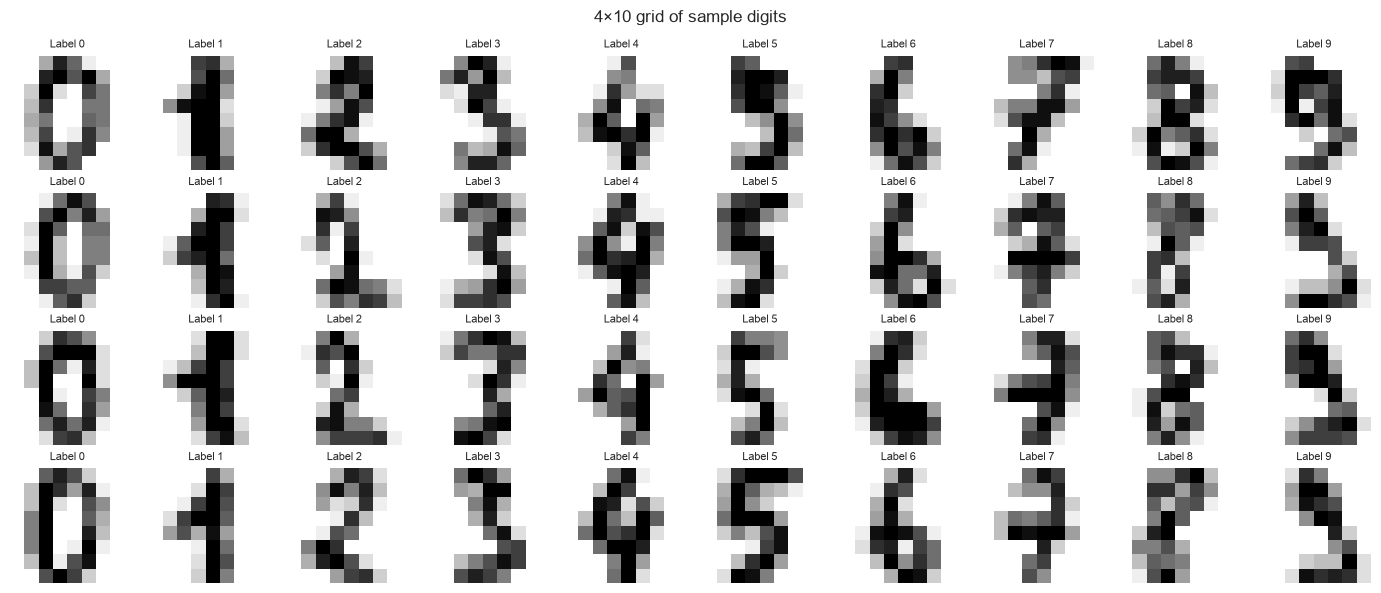

In [3]:
fig, axes = plt.subplots(4, 10, figsize=(14, 6))
for d in range(10):
    idx = np.where(y_raw == d)[0][:4]
    for r, i in enumerate(idx):
        axes[r, d].imshow(images_raw[i], cmap='gray_r')
        axes[r, d].set_title(f'Label {d}', fontsize=8)
        axes[r, d].axis('off')
plt.suptitle('4×10 grid of sample digits')
plt.tight_layout()
plt.show()

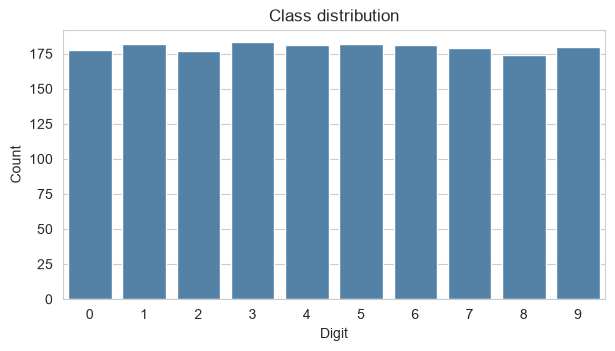

{0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


In [4]:
counts = pd.Series(y_raw).value_counts().sort_index()
plt.figure(figsize=(7, 3.5))
sns.barplot(x=counts.index, y=counts.values, color='steelblue')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.title('Class distribution')
plt.show()
print(counts.to_dict())

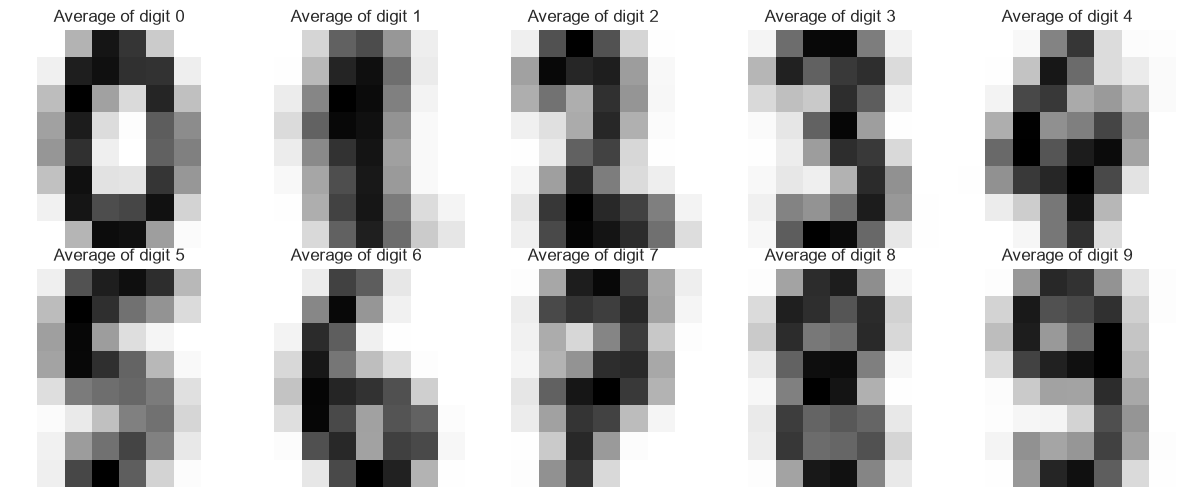

Pixels that are always zero: [0, 32, 39]


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for d, ax in enumerate(axes.ravel()):
    ax.imshow(images_raw[y_raw == d].mean(axis=0), cmap='gray_r')
    ax.set_title(f'Average of digit {d}')
    ax.axis('off')
plt.tight_layout()
plt.show()
always_zero = np.where(X_raw.max(axis=0) == 0)[0]
print('Pixels that are always zero:', always_zero.tolist())

**Step 1 note:** Loaded the data into a DataFrame, confirmed the shape (1797×64 + target), 0–16 pixel range and no missing values. The sample grid and average images show how each digit looks, the class counts are almost balanced, and the always-zero pixels (image corners) carry no information, so they will be removed later.

## Step 2 – Data cleaning

In [6]:
X_dmg = X_raw.copy()
n, p = X_dmg.shape

nan_mask = rng.random(X_dmg.shape) < 0.03
X_dmg[nan_mask] = np.nan

live_pixels = np.setdiff1d(np.arange(p), always_zero)
noisy_images = rng.choice(n, size=int(0.05 * n), replace=False)
for i in noisy_images:
    pix = rng.choice(live_pixels, size=int(0.10 * p), replace=False)
    X_dmg[i, pix] = rng.choice([0, 16], size=len(pix))

dup_idx = rng.choice(n, size=20, replace=False)
X_dmg = np.vstack([X_dmg, X_dmg[dup_idx]])
y_dmg = np.concatenate([y_raw, y_raw[dup_idx]])

print('Damaged data shape:', X_dmg.shape)
print('NaN pixels injected:', int(np.isnan(X_dmg).sum()), f'({np.isnan(X_dmg).mean()*100:.2f}%)')
print('Images with salt-and-pepper noise:', len(noisy_images))
print('Duplicate images added:', len(dup_idx))

Damaged data shape: (1817, 64)
NaN pixels injected: 3489 (3.00%)
Images with salt-and-pepper noise: 89
Duplicate images added: 20


In [7]:
df_dmg = pd.DataFrame(X_dmg)
df_dmg['target'] = y_dmg
print('Rows with at least one NaN:', int(df_dmg.iloc[:, :64].isna().any(axis=1).sum()))
print('Duplicate rows detected:', int(df_dmg.duplicated().sum()))

df_clean = df_dmg.drop_duplicates().reset_index(drop=True)
X_clean = df_clean.iloc[:, :64].values
y_clean = df_clean['target'].values.astype(int)
print('Shape after removing duplicates:', X_clean.shape)

Rows with at least one NaN: 1541
Duplicate rows detected: 20
Shape after removing duplicates: (1797, 64)


In [8]:
demo_imputer = SimpleImputer(strategy='median')
X_demo = demo_imputer.fit_transform(X_clean)
print('NaN left after median imputation:', int(np.isnan(X_demo).sum()))
vt = VarianceThreshold(threshold=0.0).fit(X_demo)
removed = np.where(~vt.get_support())[0]
print('Constant (zero-variance) pixels removed:', removed.tolist())

NaN left after median imputation: 0
Constant (zero-variance) pixels removed: [0, 32, 39]


**Step 2 note:** Simulated damaged scans with `random_state=42`: 3% of pixels set to NaN, salt-and-pepper noise (random 0s and 16s) on 5% of images, and 20 duplicate images. The noise is applied only to pixels that are not always zero, so the dead border pixels stay constant and `VarianceThreshold` can remove them. Duplicates are detected and dropped. Median imputation and `VarianceThreshold` are shown here only to demonstrate the fix; in the final model they sit inside the Pipeline and are fitted on the training set only, which avoids data leakage.

## Step 3 – Data transformation

In [9]:
skf3 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def quick_pipe(scaler, clf):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('vt', VarianceThreshold()), ('sc', scaler), ('clf', clf)])

scalers = {'No scaling': 'passthrough', 'MinMaxScaler': MinMaxScaler(), 'StandardScaler': StandardScaler()}
rows = []
for sname, sc in scalers.items():
    for mname, clf in [('KNN', KNeighborsClassifier()), ('SVM', SVC())]:
        s = cross_val_score(quick_pipe(sc, clf), X_clean, y_clean, cv=skf3, scoring='accuracy')
        rows.append({'Scaler': sname, 'Model': mname, 'CV accuracy': s.mean(), 'Std': s.std()})
scale_cmp = pd.DataFrame(rows).pivot(index='Scaler', columns='Model', values='CV accuracy')
scale_cmp['Mean'] = scale_cmp.mean(axis=1)
scale_cmp.round(4)

Model,KNN,SVM,Mean
Scaler,,,
MinMaxScaler,0.9839,0.9805,0.9822
No scaling,0.9839,0.9805,0.9822
StandardScaler,0.9566,0.9644,0.9605


In [10]:
best_scaler_name = scale_cmp.drop(index='No scaling')['Mean'].idxmax()
SCALER_CLASS = {'MinMaxScaler': MinMaxScaler, 'StandardScaler': StandardScaler}[best_scaler_name]
print('Scaler selected for the final pipeline:', best_scaler_name)

Scaler selected for the final pipeline: MinMaxScaler


**Step 3 note:** Compared no scaling, MinMaxScaler (maps pixels to [0, 1]) and StandardScaler (zero mean, unit variance) on KNN and SVM using 5-fold CV. KNN and SVM are distance/kernel based so scaling can change their results; the scaler with the higher mean accuracy is selected automatically for the final pipeline.

## Step 4 – Feature engineering

In [11]:
class HandFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        img = X.reshape(-1, 8, 8)
        rows = img.sum(axis=2)
        cols = img.sum(axis=1)
        ink = X.sum(axis=1, keepdims=True)
        sym = 1 - np.abs(img - img[:, :, ::-1]).mean(axis=(1, 2)) / 16
        return np.hstack([X, rows, cols, ink, sym.reshape(-1, 1)])

hf_demo = HandFeatures().fit_transform(X_demo)
print('Features before:', X_demo.shape[1], '| after hand-crafted features:', hf_demo.shape[1])
print('Added: 8 row sums + 8 column sums + total ink + horizontal-symmetry score')

Features before: 64 | after hand-crafted features: 82
Added: 8 row sums + 8 column sums + total ink + horizontal-symmetry score


In [12]:
pd.DataFrame({'total_ink': hf_demo[:, -2], 'h_symmetry': hf_demo[:, -1], 'digit': y_clean}).groupby('digit').mean().round(3)

,total_ink,h_symmetry
digit,,
0,317.149,0.862
1,312.901,0.782
2,314.251,0.744
3,307.224,0.760
4,311.448,0.796
5,307.783,0.750
6,312.663,0.731
7,304.025,0.759
8,329.899,0.807


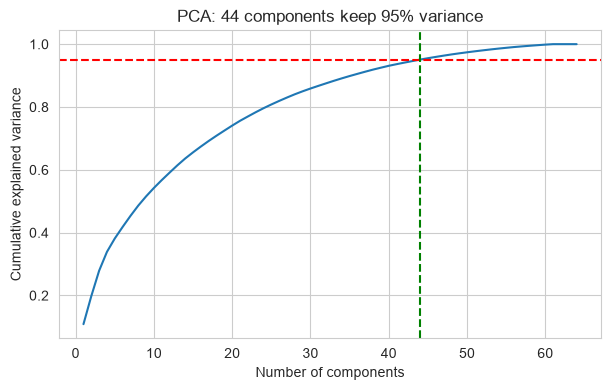

Components for 95% variance: 44


In [13]:
X_sc_demo = StandardScaler().fit_transform(X_demo)
pca_full = PCA().fit(X_sc_demo)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum)
plt.axhline(0.95, color='r', ls='--')
plt.axvline(n95, color='g', ls='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title(f'PCA: {n95} components keep 95% variance')
plt.show()
print('Components for 95% variance:', n95)

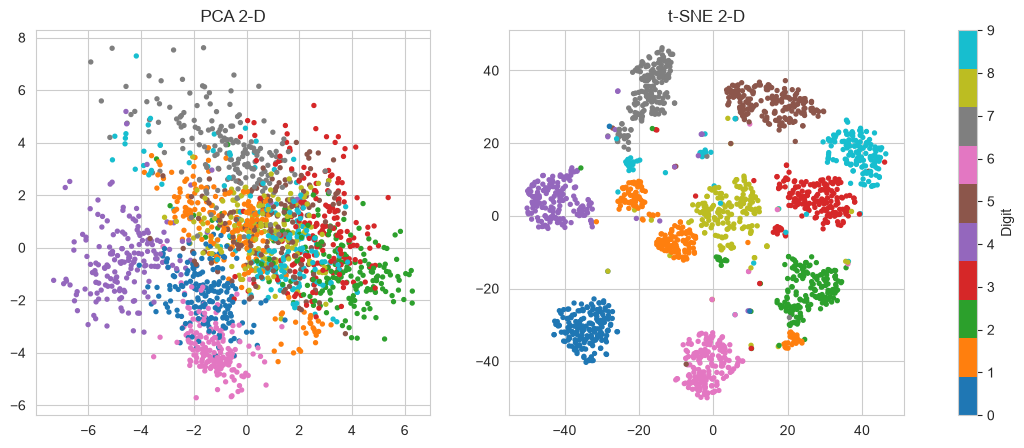

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
Z_pca = PCA(n_components=2).fit_transform(X_sc_demo)
sc1 = axes[0].scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_clean, cmap='tab10', s=8)
axes[0].set_title('PCA 2-D')
Z_tsne = TSNE(n_components=2, random_state=42, init='pca').fit_transform(X_sc_demo)
sc2 = axes[1].scatter(Z_tsne[:, 0], Z_tsne[:, 1], c=y_clean, cmap='tab10', s=8)
axes[1].set_title('t-SNE 2-D')
fig.colorbar(sc2, ax=axes, label='Digit')
plt.show()

In [15]:
def fe_pipe(use_hand, use_pca, clf=None):
    steps = [('imp', SimpleImputer(strategy='median'))]
    if use_hand:
        steps.append(('hf', HandFeatures()))
    steps += [('vt', VarianceThreshold()), ('sc', SCALER_CLASS())]
    if use_pca:
        steps.append(('pca', PCA(n_components=0.95, random_state=42)))
    steps.append(('clf', clf if clf is not None else SVC()))
    return Pipeline(steps)

fe_rows = []
for label, uh, up in [('Raw pixels', False, False), ('Pixels + hand-crafted', True, False), ('Pixels + PCA 95%', False, True), ('Pixels + hand-crafted + PCA 95%', True, True)]:
    for mname, clf in [('KNN', KNeighborsClassifier()), ('SVM', SVC())]:
        s = cross_val_score(fe_pipe(uh, up, clf), X_clean, y_clean, cv=skf3, scoring='accuracy')
        fe_rows.append({'Features': label, 'Model': mname, 'CV accuracy': s.mean()})
fe_cmp = pd.DataFrame(fe_rows).pivot(index='Features', columns='Model', values='CV accuracy')
fe_cmp.round(4)

Model,KNN,SVM
Features,,
Pixels + PCA 95%,0.9844,0.9872
Pixels + hand-crafted,0.9822,0.9816
Pixels + hand-crafted + PCA 95%,0.9827,0.9878
Raw pixels,0.9839,0.9805


In [16]:
USE_HAND = bool(fe_cmp.loc['Pixels + hand-crafted'].mean() > fe_cmp.loc['Raw pixels'].mean())
USE_PCA = bool(fe_cmp.loc['Pixels + PCA 95%'].mean() > fe_cmp.loc['Raw pixels'].mean())
print('Use hand-crafted features in final pipeline:', USE_HAND)
print('Use PCA in final pipeline:', USE_PCA)

Use hand-crafted features in final pipeline: False
Use PCA in final pipeline: True


**Step 4 note:** Built 18 hand-crafted features: 8 row sums, 8 column sums, total ink and a horizontal-symmetry score (computed inside a custom transformer so it works in a Pipeline). PCA shows how many components keep 95% variance, and PCA/t-SNE plots show that digits form clear clusters. The four feature sets are compared with KNN and SVM using CV, and the final pipeline keeps hand-crafted features and/or PCA only if they raise accuracy over raw pixels.

## Step 5 – Train–test split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, stratify=y_clean, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train class share:', np.round(np.bincount(y_train) / len(y_train), 3).tolist())
print('Test class share :', np.round(np.bincount(y_test) / len(y_test), 3).tolist())

Train: (1437, 64) | Test: (360, 64)
Train class share: [0.099, 0.102, 0.099, 0.102, 0.101, 0.101, 0.101, 0.1, 0.097, 0.1]
Test class share : [0.1, 0.1, 0.097, 0.103, 0.1, 0.103, 0.1, 0.1, 0.097, 0.1]


**Step 5 note:** Stratified 80/20 split with `random_state=42` so each digit has the same share in train and test. Imputation, variance filtering, feature creation, scaling and PCA are all inside the Pipeline, so they learn only from the training data.

## Step 6 – Model building

In [18]:
def make_pipe(clf):
    return fe_pipe(USE_HAND, USE_PCA, clf)

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM (RBF)': SVC(kernel='rbf', probability=False, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'MLP': MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42),
}
fitted, train_time = {}, {}
for name, clf in models.items():
    pipe = make_pipe(clf)
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time[name] = time.perf_counter() - t0
    fitted[name] = pipe
    print(f'{name:20s} trained in {train_time[name]:.3f}s')

Logistic Regression  trained in 0.033s
KNN                  trained in 0.016s
SVM (RBF)            trained in 0.058s
Random Forest        trained in 0.521s
MLP                  trained in 1.142s


**Step 6 note:** Trained the five required models (Logistic Regression, KNN, SVM with RBF kernel, Random Forest, MLP), each wrapped in the same preprocessing Pipeline so the comparison is fair.

## Step 7 – Model evaluation

In [19]:
results, preds, pred_ms = [], {}, {}
for name, pipe in fitted.items():
    t0 = time.perf_counter()
    yp = pipe.predict(X_test)
    pred_ms[name] = (time.perf_counter() - t0) / len(X_test) * 1000
    preds[name] = yp
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, yp, average='macro')
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, yp), 'Macro Precision': pr, 'Macro Recall': rc, 'Macro F1': f1})
res_df = pd.DataFrame(results).set_index('Model')
res_df.round(4)

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Logistic Regression,0.9472,0.9485,0.9467,0.9467
KNN,0.9833,0.9838,0.9830,0.9830
SVM (RBF),0.9861,0.9866,0.9860,0.9860
Random Forest,0.9611,0.9630,0.9608,0.9604
MLP,0.9639,0.9644,0.9636,0.9636


In [20]:
for name, yp in preds.items():
    print('=' * 60)
    print(name)
    print(classification_report(y_test, yp, digits=3))

Logistic Regression
              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.865     0.889     0.877        36
           2      1.000     1.000     1.000        35
           3      0.974     1.000     0.987        37
           4      0.897     0.972     0.933        36
           5      0.925     1.000     0.961        37
           6      0.919     0.944     0.932        36
           7      1.000     0.972     0.986        36
           8      0.935     0.829     0.879        35
           9      0.970     0.889     0.928        36

    accuracy                          0.947       360
   macro avg      0.949     0.947     0.947       360
weighted avg      0.948     0.947     0.947       360

KNN
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.923     1.000     0.960        36
           2      1.000     1.000     1.000        35


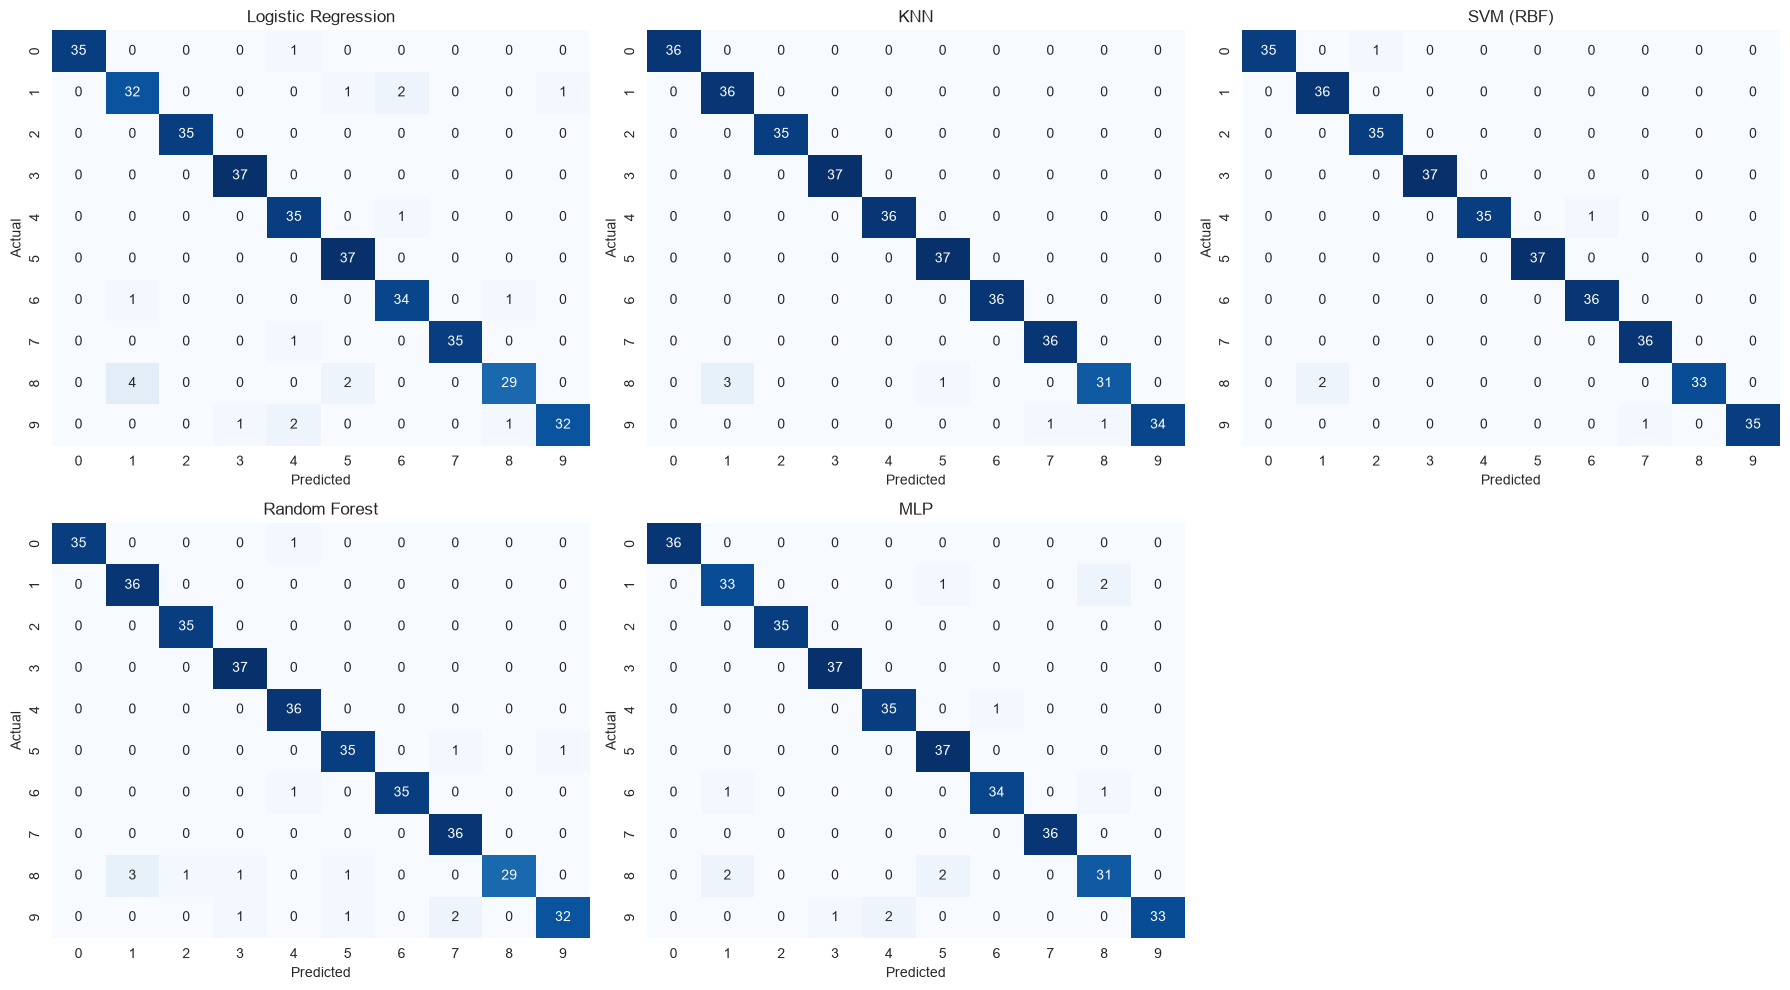

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, yp) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

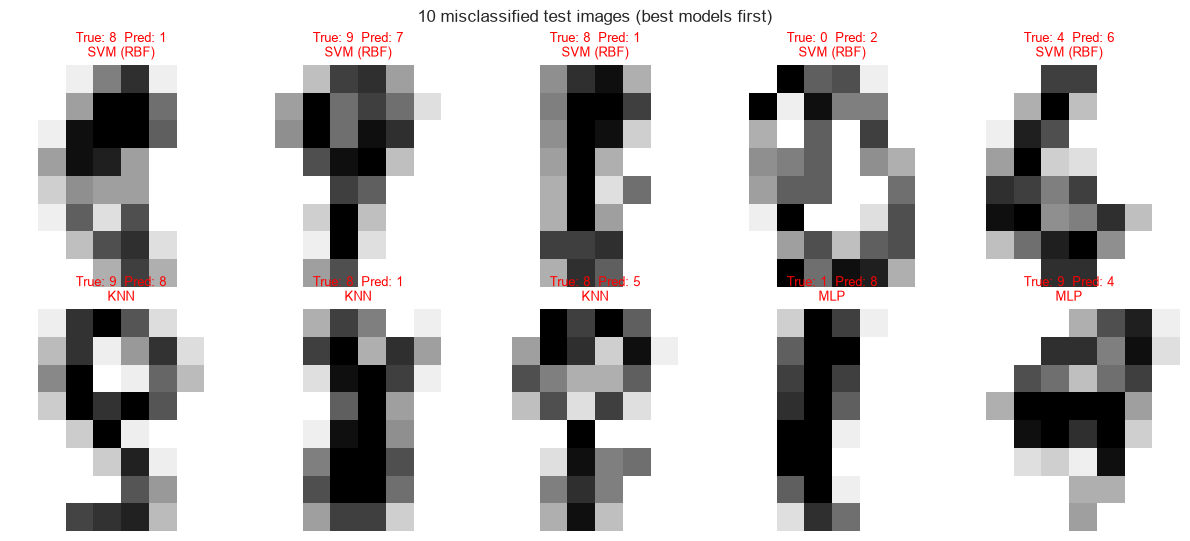

Images shown: 10
SVM (RBF): 5 misclassified
KNN: 6 misclassified
MLP: 13 misclassified
Random Forest: 14 misclassified
Logistic Regression: 19 misclassified


In [22]:
best_name = res_df['Accuracy'].idxmax()
X_test_imp = fitted[best_name].named_steps['imp'].transform(X_test)
order = res_df['Accuracy'].sort_values(ascending=False).index.tolist()
shown, seen = [], set()
for name in order:
    for i in np.where(preds[name] != y_test)[0]:
        if i not in seen and len(shown) < 10:
            seen.add(i)
            shown.append((i, name, preds[name][i]))
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, (i, name, pr) in zip(axes.ravel(), shown):
    ax.imshow(X_test_imp[i].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'True: {y_test[i]}  Pred: {pr}\n{name}', fontsize=9, color='red')
    ax.axis('off')
for ax in axes.ravel()[len(shown):]:
    ax.axis('off')
plt.suptitle('10 misclassified test images (best models first)')
plt.tight_layout()
plt.show()
print('Images shown:', len(shown))
for name in order:
    print(f'{name}: {int((preds[name] != y_test).sum())} misclassified')

**Step 7 note:** Evaluated every model on the untouched test set with accuracy, macro precision/recall/F1, a per-class classification report and a 10×10 confusion-matrix heatmap. Ten wrong predictions (taken from the best models first, then weaker ones if needed) are displayed with true and predicted labels, which shows which digits look alike. Macro averages treat every digit equally.

## Step 8 – Cross-validation

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, clf in models.items():
    cv_scores[name] = cross_val_score(make_pipe(clf), X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
cv_df = pd.DataFrame({'CV mean': {k: v.mean() for k, v in cv_scores.items()}, 'CV std': {k: v.std() for k, v in cv_scores.items()}})
cv_df['CV (mean ± std)'] = cv_df.apply(lambda r: f"{r['CV mean']:.4f} ± {r['CV std']:.4f}", axis=1)
cv_df.sort_values('CV mean', ascending=False)[['CV (mean ± std)']]

,CV (mean ± std)
SVM (RBF),0.9854 ± 0.0067
KNN,0.9826 ± 0.0085
MLP,0.9680 ± 0.0089
Random Forest,0.9652 ± 0.0088
Logistic Regression,0.9596 ± 0.0047


Two best models by CV: ['SVM (RBF)', 'KNN']


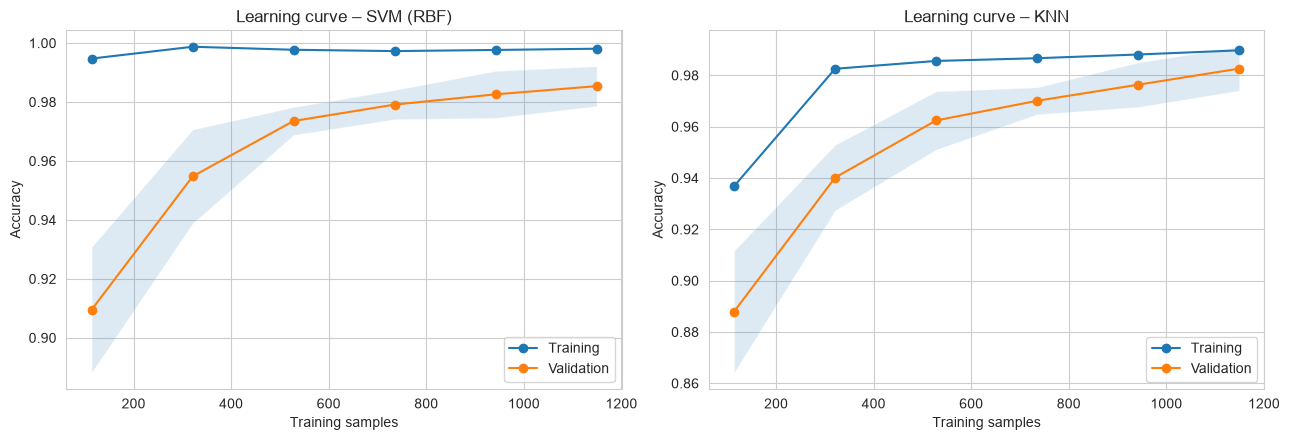

In [24]:
top2 = cv_df['CV mean'].sort_values(ascending=False).index[:2].tolist()
print('Two best models by CV:', top2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, top2):
    sizes, tr, va = learning_curve(make_pipe(models[name]), X_train, y_train, cv=cv, train_sizes=np.linspace(0.1, 1.0, 6), scoring='accuracy', n_jobs=-1)
    ax.plot(sizes, tr.mean(axis=1), 'o-', label='Training')
    ax.plot(sizes, va.mean(axis=1), 'o-', label='Validation')
    ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.15)
    ax.set_title(f'Learning curve – {name}')
    ax.set_xlabel('Training samples')
    ax.set_ylabel('Accuracy')
    ax.legend()
plt.tight_layout()
plt.show()

**Step 8 note:** Ran 5-fold Stratified CV on the training set only and reported mean ± std accuracy for all five models. The learning curves of the two best models show whether more data would help (validation curve still rising) or whether the model already overfits (large gap between curves).

## Step 9 – Hyperparameter tuning

In [25]:
grids = {
    'Logistic Regression': {'clf__C': [0.1, 1, 10, 100]},
    'KNN': {'clf__n_neighbors': [1, 3, 5, 7, 9], 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]},
    'SVM (RBF)': {'clf__C': [1, 10, 100], 'clf__gamma': ['scale', 0.1, 0.01, 0.001]},
    'Random Forest': {'clf__n_estimators': [100, 300], 'clf__max_depth': [None, 20], 'clf__max_features': ['sqrt', 'log2']},
    'MLP': {'clf__hidden_layer_sizes': [(64,), (128,), (128, 64)], 'clf__alpha': [1e-4, 1e-3, 1e-2]},
}
tuned, tune_rows = {}, []
for name in top2:
    gs = GridSearchCV(make_pipe(models[name]), grids[name], cv=cv, scoring='accuracy', n_jobs=-1)
    t0 = time.perf_counter()
    gs.fit(X_train, y_train)
    tt = time.perf_counter() - t0
    tuned[name] = gs.best_estimator_
    yp_t = gs.best_estimator_.predict(X_test)
    tune_rows.append({'Model': name, 'Best params': gs.best_params_, 'Best CV score': gs.best_score_, 'Default CV': cv_df.loc[name, 'CV mean'], 'Default test acc': res_df.loc[name, 'Accuracy'], 'Tuned test acc': accuracy_score(y_test, yp_t), 'Search time (s)': tt})
tune_df = pd.DataFrame(tune_rows).set_index('Model')
for name, r in tune_df.iterrows():
    print(name, '->', r['Best params'])
tune_df.drop(columns='Best params').round(4)

SVM (RBF) -> {'clf__C': 10, 'clf__gamma': 'scale'}
KNN -> {'clf__n_neighbors': 1, 'clf__p': 1, 'clf__weights': 'uniform'}


,Best CV score,Default CV,Default test acc,Tuned test acc,Search time (s)
Model,,,,,
SVM (RBF),0.9889,0.9854,0.9861,0.9833,0.7903
KNN,0.9847,0.9826,0.9833,0.9806,0.6591


**Step 9 note:** Tuned the two best models from Step 8 with `GridSearchCV` (5-fold, accuracy). Search spaces cover the main hyperparameters: C and gamma for SVM, neighbours/weights/distance for KNN, size and regularisation for MLP, trees/depth/features for Random Forest and C for Logistic Regression. Tuned vs default CV and test accuracy are compared above; accuracy is the right metric because the classes are balanced.

## Step 10 – Model selection

In [26]:
rows = []
for name in top2:
    t0 = time.perf_counter()
    yp_t = tuned[name].predict(X_test)
    ms = (time.perf_counter() - t0) / len(X_test) * 1000
    rows.append({'Model': name, 'Default CV': cv_df.loc[name, 'CV mean'], 'Default test': res_df.loc[name, 'Accuracy'], 'Tuned CV': tune_df.loc[name, 'Best CV score'], 'Tuned test': accuracy_score(y_test, yp_t), 'Train time (s)': train_time[name], 'Predict ms/image': ms})
for name in models:
    if name not in top2:
        rows.append({'Model': name, 'Default CV': cv_df.loc[name, 'CV mean'], 'Default test': res_df.loc[name, 'Accuracy'], 'Tuned CV': np.nan, 'Tuned test': np.nan, 'Train time (s)': train_time[name], 'Predict ms/image': pred_ms[name]})
sel_df = pd.DataFrame(rows).set_index('Model')
sel_df.round(4)

,Default CV,Default test,Tuned CV,Tuned test,Train time (s),Predict ms/image
Model,,,,,,
SVM (RBF),0.9854,0.9861,0.9889,0.9833,0.0580,0.0693
KNN,0.9826,0.9833,0.9847,0.9806,0.0164,0.0558
Logistic Regression,0.9596,0.9472,NaN,NaN,0.0331,0.0054
Random Forest,0.9652,0.9611,NaN,NaN,0.5215,0.1921
MLP,0.9680,0.9639,NaN,NaN,1.1420,0.0067


In [27]:
final_name = tune_df['Best CV score'].idxmax()
final_model = tuned[final_name]
print('Final model:', final_name)
print('Tuned test accuracy:', round(accuracy_score(y_test, final_model.predict(X_test)), 4))

cm = confusion_matrix(y_test, final_model.predict(X_test))
pairs = []
for i in range(10):
    for j in range(i + 1, 10):
        pairs.append((i, j, cm[i, j] + cm[j, i]))
pairs = sorted(pairs, key=lambda t: -t[2])[:5]
print('Most confused digit pairs (true<->predicted, total errors):')
for i, j, c in pairs:
    print(f'  {i} <-> {j}: {c}')

Final model: SVM (RBF)
Tuned test accuracy: 0.9833
Most confused digit pairs (true<->predicted, total errors):
  1 <-> 8: 2
  0 <-> 2: 1
  3 <-> 9: 1
  4 <-> 6: 1
  7 <-> 9: 1


**Step 10 note:** The comparison table lists default vs tuned performance, CV vs test score, training time and prediction time per image. The final model is the tuned model with the best CV score; for a postal service, high accuracy with fast per-image prediction matters because millions of digits are read. Digit pairs with the most mistakes (listed above) are usually shapes that look alike at only 8×8 resolution (for example 1/8, 3/9, 7/9), where a few pixels decide the class.

## Step 11 – Save the model to your local drive

Saved to C:\Users\khana\Ds_group-5\models\q5_digits_best_model.pkl (286.0 KB)
Reloaded predictions : [5, 2, 8, 1, 7]
True labels          : [5, 2, 8, 1, 7]
Matches in-memory model: True


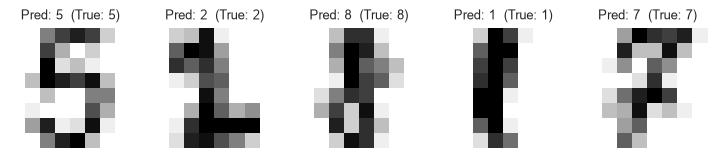

In [28]:
os.makedirs('models', exist_ok=True)
path = os.path.join('models', 'q5_digits_best_model.pkl')
joblib.dump(final_model, path)
print('Saved to', os.path.abspath(path), f'({os.path.getsize(path)/1024:.1f} KB)')

loaded = joblib.load(path)
sample = X_test[:5]
pred_loaded = loaded.predict(sample)
print('Reloaded predictions :', pred_loaded.tolist())
print('True labels          :', y_test[:5].tolist())
print('Matches in-memory model:', bool(np.array_equal(pred_loaded, final_model.predict(sample))))

sample_imp = loaded.named_steps['imp'].transform(sample)
fig, axes = plt.subplots(1, 5, figsize=(9, 2.2))
for ax, img, pr, tr in zip(axes, sample_imp, pred_loaded, y_test[:5]):
    ax.imshow(img.reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Pred: {pr}  (True: {tr})', fontsize=9)
    ax.axis('off')
plt.show()

**Step 11 note:** Saved the complete fitted pipeline (imputer + feature creation + variance filter + scaler + optional PCA + classifier) with `joblib` into the `models` folder next to the notebook, reloaded it from disk and predicted 5 test images. The reloaded predictions match the in-memory model, which proves the file works on raw 64-pixel input.

Predicted: 6 | True: 6


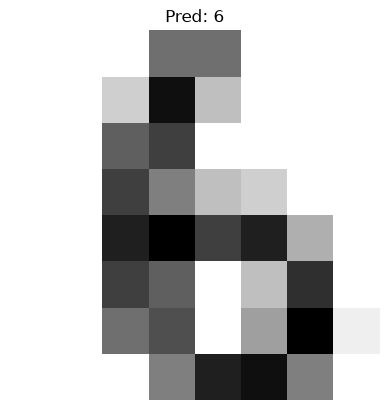

In [4]:
import joblib
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

d = load_digits()
model = joblib.load(r"C:\Users\khana\Ds_group-5\models\q5_digits_best_model.pkl")

i = 1222

p = model.predict(d.data[[i]])[0]
print("Predicted:", p, "| True:", d.target[i])
plt.imshow(d.images[i], cmap="gray_r")
plt.title(f"Pred: {p}")
plt.axis("off")
plt.show()